In [1]:
import os
import sys

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_13/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# Бустинг с признаками против foundation-модели

В лидербордах foundation-модели обходят всё остальное, и Chronos-2 умеет принимать ковариаты. Значит ли это, что градиентный бустинг с признаками из занятия 9 больше не нужен? Проверим на задаче, где у бизнеса много знаний о будущем: промоакции, скидки, закрытия магазинов, праздники.

План:
1. что говорит fev-bench про бустинг;
2. синтетика с промо, где мы знаем правильный ответ;
3. реальные данные: 300 магазинов Rossmann с бизнес-признаками;
4. дообучение Chronos-2: что оно исправляет и чего исправить не может;
5. интерпретация: как понять, на что опирается каждая модель.

Все выводы сохранены, поэтому на семинаре ноутбук можно читать, ничего не запуская. Они получены на RTX 3090, там весь ноутбук выполняется примерно за 3.5 минуты: дольше всего идут раздел 3 (Chronos-2 и LightGBM на трёх окнах, абляция) и дообучение в разделе 4, примерно по полторы минуты.

Ноутбук работает и на CPU, но с GPU (в Colab **Runtime → Change runtime type → T4 GPU**) Chronos-2 считает в несколько раз быстрее. На T4 весь ноутбук идёт около 22 минут: T4 медленнее 3090, а у Colab всего два ядра CPU для LightGBM. Дольше всего там идут дообучение в разделе 4 (около 10 минут на Rossmann и синтетику вместе), раздел 3 (около 6 минут) и вклады признаков в разделе 5 (около 3 минут). Дообучение в разделе 4 на CPU сокращено до 3 шагов, только чтобы проверить код: цифры из текста там получены на GPU.

In [2]:
import time
import warnings

import datasets
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from chronos import Chronos2Pipeline

warnings.filterwarnings("ignore")
datasets.disable_progress_bars()
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pipe = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=DEVICE)
print(f"torch {torch.__version__}, lightgbm {lgb.__version__}, device {DEVICE}")

torch 2.14.1+cu130, lightgbm 4.6.0, device cuda


## 1. Что говорит fev-bench

В fev-bench среди моделей есть LightGBM: это [mlforecast](https://github.com/Nixtla/mlforecast) с лагами, календарными признаками, статическими и известными будущими ковариатами задачи. Optuna подбирает только предобработку (разности, масштабирование, сглаженные лаги), гиперпараметры LightGBM фиксированы, прошлые ковариаты отбрасываются, а квантили совпадают с точечным прогнозом, поэтому сравниваем по MASE. Признаков под конкретную задачу ему никто не придумывал. Возьмём результаты из репозитория fev на том же коммите, что в первом ноутбуке семинара.

In [3]:
FEV_RESULTS = (
    "https://raw.githubusercontent.com/autogluon/fev/9cf943c388e5cfaf352175ea3c69e408b197d997/"
    "benchmarks/fev_bench/results/"
)
fev_mase = pd.DataFrame(
    {
        label: pd.read_csv(FEV_RESULTS + name + ".csv").set_index("task_name")["MASE"]
        for label, name in [
            ("LightGBM", "lightgbm"),
            ("Chronos-2", "chronos-2"),
            ("Seasonal Naive", "seasonal_naive"),
        ]
    }
)
ratio = fev_mase["LightGBM"] / fev_mase["Chronos-2"]
print(
    f"LightGBM точнее Chronos-2 по MASE на {(ratio < 1).sum()} задачах из {len(ratio)}, "
    f"больше чем на 10% на {(ratio < 0.9).sum()}"
)
RETAIL = [
    "rossmann_1D",
    "rossmann_1W",
    "rohlik_sales_1D",
    "rohlik_orders_1D",
    "m5_1D",
    "favorita_stores_1D",
    "walmart",
    "hermes",
]
fev_mase.loc[RETAIL].assign(**{"LightGBM / Chronos-2": ratio}).round(3)

LightGBM точнее Chronos-2 по MASE на 17 задачах из 100, больше чем на 10% на 5


,LightGBM,Chronos-2,Seasonal Naive,LightGBM / Chronos-2
task_name,,,,
rossmann_1D,0.341,0.356,0.789,0.959
rossmann_1W,0.678,0.371,0.796,1.826
rohlik_sales_1D,1.342,1.102,1.615,1.219
rohlik_orders_1D,1.253,1.187,1.778,1.056
m5_1D,0.906,0.880,1.224,1.030
favorita_stores_1D,1.237,1.140,1.759,1.085
walmart,1.246,0.817,1.524,1.525
hermes,1.183,0.776,1.995,1.524


Задачи выше это ритейл: продажи магазинов и товаров с ценами, промо и праздниками в ковариатах. Почти везде LightGBM хуже Chronos-2, иногда в полтора раза (walmart, hermes). Там, где LightGBM всё-таки выигрывает больше чем на 10%, задачи другие: ковид, туризм, макроэкономика. Это короткие ряды со структурными сдвигами.

Значит, бустинг без признаков под задачу и без подбора гиперпараметров foundation-модели проигрывает. Дальше проверим другое: что будет, если дать ему признаки, в которые мы вложили знание о бизнесе.

## 2. Синтетика: эффект скидки, которого не было в истории

Начнём с данных, где правильный ответ известен. 120 товаров, по два года дневных продаж: недельная и годовая сезонность, шум и промоакции по 7 дней. Эффект промо устроен так, как часто бывает на практике:
- скидки меньше ~15% почти не меняют продажи, около 20% эффект резко включается, дальше выходит на насыщение;
- сила эффекта зависит от категории товара: в категории A продажи на пике растут на 40%, в B на 80%, в C на 120%.

Главное в постановке: у половины товаров в истории были **только мелкие скидки** (5–12%), у другой половины глубокие (22–40%). В прогнозном окне на неделю запланирована акция со скидкой 30% для всех товаров. Так бывает, когда маркетинг впервые даёт на товар глубокую скидку.

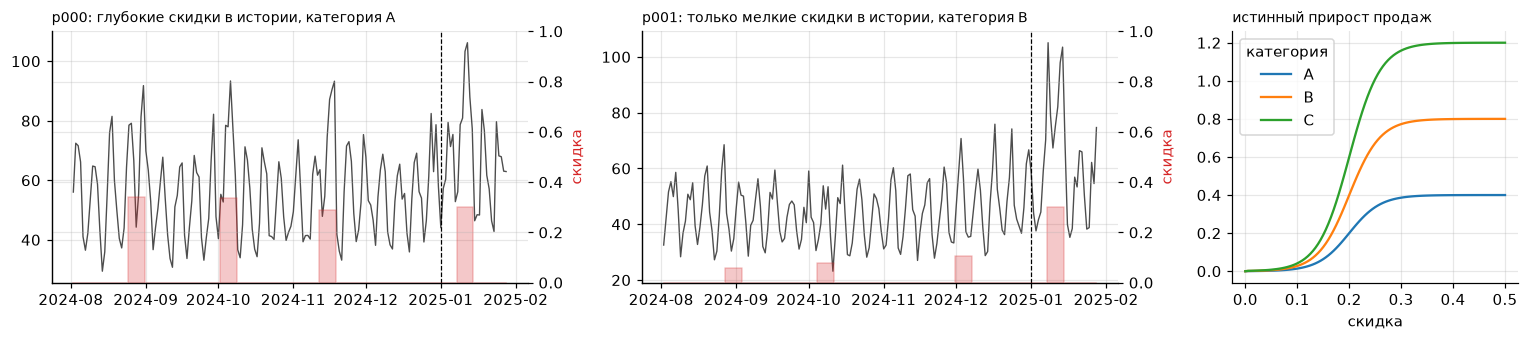

In [4]:
ELASTICITY = {"A": 0.4, "B": 0.8, "C": 1.2}
N_ITEMS, T, H_SYN = 120, 730, 28


def true_uplift(depth, category):
    # прирост продаж от скидки: включается около 20%, дальше насыщение
    return ELASTICITY[category] / (1 + np.exp(-(depth - 0.2) / 0.03)) * (depth > 0)


rng = np.random.default_rng(0)
syn_dates = pd.date_range("2023-01-02", periods=T + H_SYN, freq="D")
items = []
for i in range(N_ITEMS):
    category = "ABC"[i % 3]
    deep = i % 2 == 0  # у чётных товаров в истории глубокие скидки, у нечётных только мелкие
    level = np.exp(rng.normal(4, 0.6))
    weekly = 1 + 0.3 * np.sin(2 * np.pi * (np.arange(7) + rng.integers(7)) / 7)
    discount = np.zeros(T + H_SYN)
    start = rng.integers(10, 40)
    while start < T - 7:
        discount[start : start + 7] = rng.uniform(0.22, 0.4) if deep else rng.uniform(0.05, 0.12)
        start += rng.integers(35, 60)
    discount[T + 7 : T + 14] = 0.3  # запланированная акция во второй неделе прогноза
    t = np.arange(T + H_SYN)
    yearly = 1 + 0.15 * np.sin(2 * np.pi * t / 365.25)
    noise = np.exp(rng.normal(0, 0.1, T + H_SYN))
    baseline = level * weekly[t % 7] * yearly  # ожидаемые продажи без скидки
    sales = baseline * (1 + true_uplift(discount, category)) * noise
    items.append(
        pd.DataFrame(
            {
                "item_id": f"p{i:03d}",
                "timestamp": syn_dates,
                "target": sales,
                "baseline": baseline,
                "discount": discount,
                "category": category,
                "history": "глубокие скидки" if deep else "только мелкие скидки",
            }
        )
    )
syn = pd.concat(items, ignore_index=True)
syn_hist = syn.timestamp < syn_dates[T]
syn_future = syn[~syn_hist].copy()
campaign = syn_future.discount.values > 0

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), gridspec_kw={"width_ratios": [2, 2, 1.2]})
for ax, item in zip(axes[:2], ["p000", "p001"]):
    s = syn[syn.item_id == item].iloc[-180:]
    ax.plot(s.timestamp, s.target, lw=0.9, color="0.3")
    ax2 = ax.twinx()
    ax2.fill_between(s.timestamp, s.discount, step="mid", alpha=0.25, color="C3")
    ax2.set_ylim(0, 1)
    ax2.set_ylabel("скидка", color="C3")
    ax.axvline(syn_dates[T], color="k", ls="--", lw=0.8)
    ax.set_title(
        f"{item}: {s.history.iloc[0]} в истории, категория {s.category.iloc[0]}",
        loc="left",
        fontsize=9,
    )
depth_grid = np.linspace(0, 0.5, 101)
for category in "ABC":
    axes[2].plot(depth_grid, [true_uplift(d, category) for d in depth_grid], label=category)
axes[2].set_xlabel("скидка")
axes[2].set_title("истинный прирост продаж", loc="left", fontsize=9)
axes[2].legend(title="категория")
fig.tight_layout()

Модели:
- **Chronos-2** без ковариат и с известной будущей ковариатой `discount`;
- **LightGBM**, одна глобальная модель на все 120 товаров. Признаки: скидка, категория, день недели, день года, недельный профиль товара (средний логарифм продаж без промо по дням недели на истории) и уровень товара. Уровень считаем так, чтобы он был известен в момент прогноза: среднее продаж без промо за 8 недель, закончившихся 28 дней назад. Учим на логарифме продаж.

In [5]:
def syn_features(frame):
    f = pd.DataFrame(index=frame.index)
    f["discount"] = frame.discount
    f["category"] = frame.category.map({"A": 0, "B": 1, "C": 2})
    f["dow"] = frame.timestamp.dt.dayofweek
    f["doy"] = frame.timestamp.dt.dayofyear
    regular = frame.target.where(frame.discount == 0)
    f["level"] = regular.groupby(frame.item_id).transform(
        lambda x: x.rolling(56, min_periods=14).mean().shift(H_SYN)
    )
    # недельный профиль товара: средний логарифм продаж без промо по дням недели на истории
    profile = np.log(frame.target.where(syn_hist & (frame.discount == 0)))
    f["item_dow_mean"] = profile.groupby([frame.item_id, f.dow]).transform("mean")
    return f


SYN_PARAMS = {
    "objective": "l2",
    "learning_rate": 0.05,
    "num_leaves": 31,
    "min_data_in_leaf": 50,
    "verbose": -1,
    "seed": 0,
}
syn_X = syn_features(syn)
syn_gbm = lgb.train(
    SYN_PARAMS, lgb.Dataset(syn_X[syn_hist], np.log(syn.target[syn_hist])), num_boost_round=500
)


def syn_chronos(future, with_discount=True, cross_learning=False, model=None):
    covariates = ["discount"] if with_discount else []
    past = syn.loc[
        syn_hist & syn.item_id.isin(future.item_id), ["item_id", "timestamp", "target", *covariates]
    ]
    pred = (model or pipe).predict_df(
        past,
        future_df=future[["item_id", "timestamp", *covariates]] if covariates else None,
        prediction_length=H_SYN,
        quantile_levels=[0.5],
        cross_learning=cross_learning,
    )
    pred = pred.set_index(["item_id", "timestamp"])["predictions"]
    return pred.reindex(pd.MultiIndex.from_frame(future[["item_id", "timestamp"]])).values


syn_preds = {
    "Chronos-2": syn_chronos(syn_future, with_discount=False),
    "Chronos-2 + скидка": syn_chronos(syn_future),
    "Chronos-2 + скидка, cross-learning": syn_chronos(syn_future, cross_learning=True),
    "LightGBM": np.exp(syn_gbm.predict(syn_X[~syn_hist])),
}
scale = (
    syn[syn_hist]
    .groupby("item_id")
    .target.apply(lambda x: np.mean(np.abs(x.values[7:] - x.values[:-7])))
)
group = syn.groupby("item_id").history.first()
rows = {}
for name, pred in syn_preds.items():
    err = (
        pd.Series(np.abs(syn_future.target.values - pred)).groupby(syn_future.item_id.values).mean()
        / scale
    )
    bias = (
        pd.Series(pred[campaign] / syn_future.target.values[campaign] - 1)
        .groupby(group.reindex(syn_future.item_id.values[campaign]).values)
        .mean()
    )
    rows[name] = {
        **{f"MASE, {g}": v for g, v in err.groupby(group).mean().items()},
        **{f"смещение в неделю акции, {g}": v for g, v in bias.items()},
    }
pd.DataFrame(rows).T.round(3)

,"MASE, глубокие скидки","MASE, только мелкие скидки","смещение в неделю акции, глубокие скидки","смещение в неделю акции, только мелкие скидки"
Chronos-2,0.985,2.263,-0.364,-0.407
Chronos-2 + скидка,0.424,2.145,-0.024,-0.375
"Chronos-2 + скидка, cross-learning",1.317,1.984,0.387,-0.317
LightGBM,0.372,0.888,0.025,0.017


У товаров с глубокими скидками в истории Chronos-2 со скидкой в ковариатах прогнозирует почти так же, как LightGBM, и неделю акции не занижает. У товаров, которые раньше видели только мелкие скидки, Chronos-2 занижает продажи в неделю акции почти на 40%, как будто ковариаты нет вовсе. LightGBM неделю акции не занижает ни у тех, ни у других товаров: смещение около +2%. MASE между группами сравнивать не стоит: у товаров с мелкими скидками в истории не было всплесков, знаменатель MASE у них маленький, и ошибка в неделю акции весит больше.

Причина в том, откуда модель берёт эффект ковариаты:
- Chronos-2 **не обучается** на наших данных. Как скидка влияет на продажи, он выводит из контекста конкретного ряда. В истории товара мелкие скидки ничего не меняли, и модель честно заключает, что скидка не влияет (поможет ли дообучение, проверим в разделе 4);
- LightGBM учится на всех товарах сразу и видит, что происходит при скидке 30% у других товаров той же категории.

Cross-learning (группа из всех 120 рядов) не спасает: у товаров с мелкими скидками занижение остаётся около 30%, а у товаров с глубокими скидками прогноз становится завышенным.

Посмотрим на это как на эксперимент «что если»: будем менять глубину скидки в неделю акции от 0 до 50% и смотреть, на сколько процентов модель поднимает прогноз.

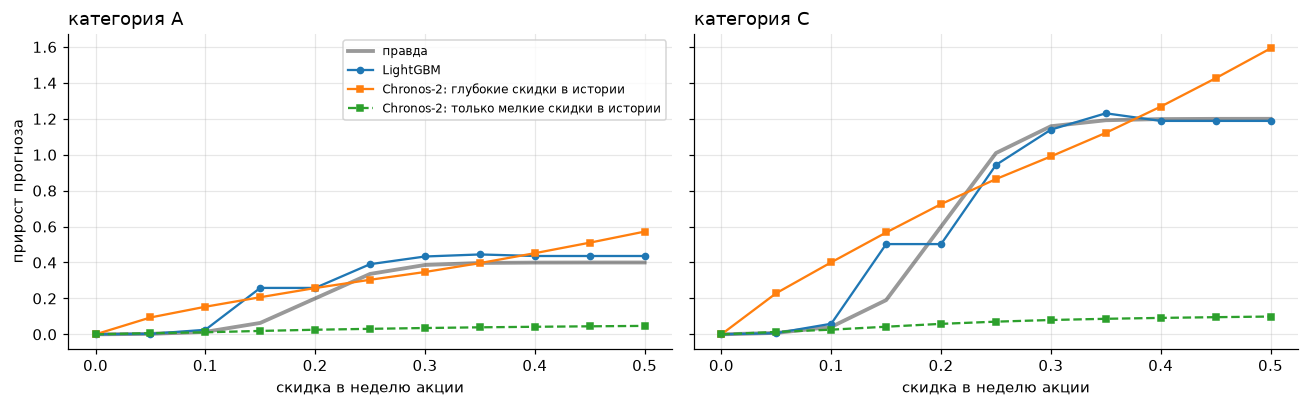

In [6]:
# для кривых хватит 10 товаров на каждое сочетание «категория A или C × история скидок»
curve_items = syn_future.drop_duplicates("item_id").groupby(["category", "history"]).head(10)
curve_future = syn_future[syn_future.item_id.isin(curve_items.item_id[curve_items.category != "B"])]
depths = np.round(np.arange(0, 0.51, 0.05), 2)
campaign_week = curve_future.timestamp.between(syn_dates[T + 7], syn_dates[T + 13]).values
full_response = {}
for depth in depths:
    scenario = syn.copy()
    scenario.loc[curve_future.index[campaign_week], "discount"] = depth
    full_response["LightGBM", depth] = np.exp(
        syn_gbm.predict(syn_features(scenario).loc[curve_future.index])
    )
    full_response["Chronos-2", depth] = syn_chronos(scenario.loc[curve_future.index])
response = {key: pred[campaign_week] for key, pred in full_response.items()}
week = curve_future[campaign_week]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, category in zip(axes, "AC"):
    ax.plot(
        depths,
        [true_uplift(d, category) for d in depths],
        color="k",
        lw=2.5,
        alpha=0.4,
        label="правда",
    )
    for model, history, style in [
        ("LightGBM", None, "-o"),
        ("Chronos-2", "глубокие скидки", "-s"),
        ("Chronos-2", "только мелкие скидки", "--s"),
    ]:
        mask = (week.category == category).values
        if history:
            mask &= (week.history == history).values
        uplift = [
            np.mean(response[model, d][mask] / response[model, 0.0][mask]) - 1 for d in depths
        ]
        ax.plot(
            depths, uplift, style, ms=4, label=model + (f": {history} в истории" if history else "")
        )
    ax.set_title(f"категория {category}", loc="left")
    ax.set_xlabel("скидка в неделю акции")
axes[0].set_ylabel("прирост прогноза")
axes[0].legend(fontsize=8)
fig.tight_layout()

Вот что значит «ковариата работает неявно»:
- у Chronos-2 нет коэффициента при скидке, который можно посмотреть или задать. Отклик получается из контекста каждого ряда заново. У товаров с глубокими скидками в истории он почти **линейный**: прирост есть и при 5%, где в действительности эффекта нет, и продолжает расти после 40%, где эффект уже насытился. У товаров с мелкими скидками отклика почти нет при любой глубине;
- LightGBM восстановил S-образную форму и для тех, и для других товаров. Но у него ступенька между 10 и 15%: скидок от 12 до 22% в данных не было, и дерево поставило границу где-то в этом промежутке. Как мы видели в занятии 9, дерево не умеет ни интерполировать гладко, ни экстраполировать.

То же верно для любой ковариаты, которая в истории ряда встречалась редко или в другом диапазоне: новая цена, первая рекламная кампания, новый тип акции.

Посмотрим на то же самое глазами менеджера, который планирует акцию: двигаем скидку и смотрим, сколько продаж за неделю акции обещает каждая модель. Возьмём два товара категории C: один с глубокими скидками в истории, другой только с мелкими. Правду в синтетике мы знаем: это ожидаемые продажи без шума. Слайдер работает при запуске ноутбука, на GitHub его не видно.

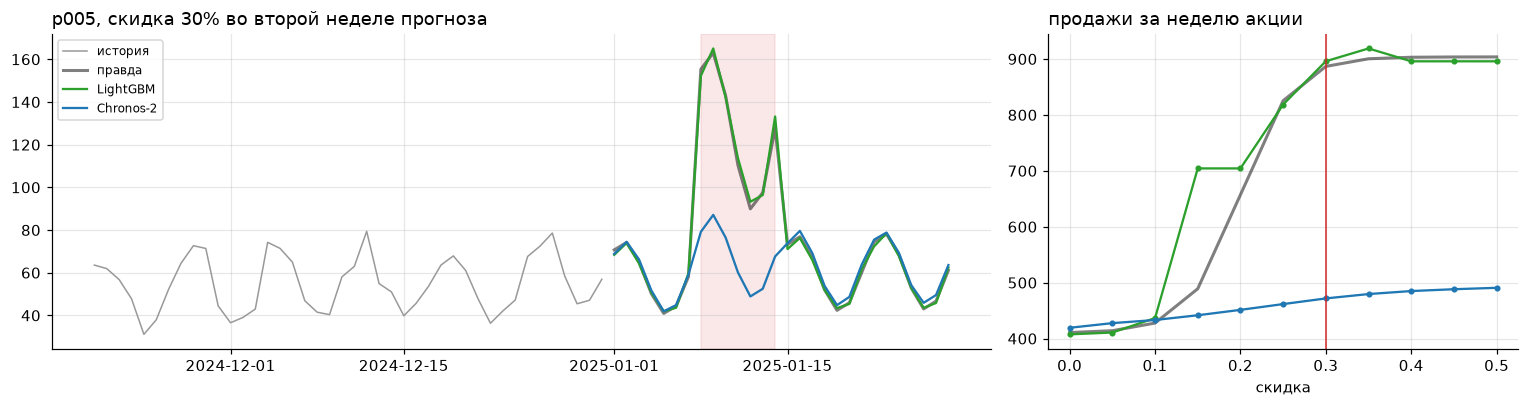

In [7]:
import ipywidgets as widgets

SLIDER_ITEMS = {
    "p002: глубокие скидки в истории": "p002",
    "p005: только мелкие скидки в истории": "p005",
}
# правда при любой скидке: ожидаемые продажи без шума
true_curve = {
    (item, depth): (
        curve_future.baseline * (1 + true_uplift(np.where(campaign_week, depth, 0.0), "C"))
    ).values[(curve_future.item_id == item).values]
    for item in SLIDER_ITEMS.values()
    for depth in depths
}


def plot_campaign(depth=0.3, item="p005"):
    rows = (curve_future.item_id == item).values
    days = curve_future.timestamp[rows]
    history = syn[syn_hist & (syn.item_id == item)].iloc[-42:]
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [2, 1]})
    axes[0].plot(history.timestamp, history.target, color="0.6", lw=1, label="история")
    axes[0].plot(days, true_curve[item, depth], color="k", lw=2, alpha=0.5, label="правда")
    for model, color in [("LightGBM", "C2"), ("Chronos-2", "C0")]:
        axes[0].plot(days, full_response[model, depth][rows], color=color, lw=1.5, label=model)
    axes[0].axvspan(syn_dates[T + 7], syn_dates[T + 13], color="C3", alpha=0.1)
    axes[0].set_title(f"{item}, скидка {depth:.0%} во второй неделе прогноза", loc="left")
    axes[0].legend(fontsize=8, loc="upper left")
    week_rows = campaign_week[rows]
    axes[1].plot(
        depths,
        [true_curve[item, d][week_rows].sum() for d in depths],
        color="k",
        lw=2,
        alpha=0.5,
        label="правда",
    )
    for model, color in [("LightGBM", "C2"), ("Chronos-2", "C0")]:
        totals = [full_response[model, d][rows][week_rows].sum() for d in depths]
        axes[1].plot(depths, totals, "-o", ms=3, color=color, label=model)
    axes[1].axvline(depth, color="C3", lw=1)
    axes[1].set_xlabel("скидка")
    axes[1].set_title("продажи за неделю акции", loc="left")
    fig.tight_layout()
    plt.show()


plot_campaign(0.3, "p005")  # статичная картинка: её видно и на GitHub

У товара с мелкими скидками в истории Chronos-2 почти не поднимает прогноз в неделю акции, LightGBM поднимает его примерно до истинного уровня. Справа видно, что у Chronos-2 продажи за неделю акции почти не зависят от скидки. Подвигайте слайдер и переключите товар: у товара с глубокими скидками в истории Chronos-2 реагирует на скидку, но почти линейно.

In [8]:
widgets.interact(
    plot_campaign,
    depth=widgets.SelectionSlider(options=list(depths), value=0.3, description="скидка"),
    item=widgets.Dropdown(options=SLIDER_ITEMS, value="p005", description="товар"),
);

interactive(children=(SelectionSlider(description='скидка', index=6, options=(np.float64(0.0), np.float64(0.05…

## 3. Rossmann: реальные продажи и бизнес-признаки

[Rossmann](https://www.kaggle.com/c/rossmann-store-sales) это дневные продажи 1115 аптек-дрогери в Германии за 2013–2015 годы, известное соревнование Kaggle, где выиграл бустинг с признаками. Берём его из того же набора данных fev-bench, случайные 300 магазинов. Прогнозируем на 48 дней, как в fev-bench, на трёх окнах подряд (март – июль 2015).

Что известно о будущем в момент прогноза:
- **ковариаты по дням**: работает ли магазин (`open`), идёт ли промо (`promo`), государственный и школьный праздник. Их получает и Chronos-2;
- **свойства магазина**: тип, ассортимент, расстояние до конкурента и когда он открылся, участие в постоянной программе Promo2 и в какие месяцы она действует. Сами по себе Chronos-2 их использовать не может: каждая ковариата стандартизуется по своему контексту, и постоянный признак превращается в ноль. Из расписания Promo2 ниже получится признак, который меняется во времени (`promo2_active`), и его Chronos-2 уже получает.

Из этого мы строим **бизнес-признаки**, как в занятии 9:
- какой по счёту день промо, сколько дней до следующего промо и после прошлого;
- сколько дней до ближайшего закрытия магазина и после него: перед праздником покупатели закупаются заранее, после закрытия приходят за пропущенным. Регулярные воскресные закрытия не считаем;
- сколько дней до ближайшего праздника и после него;
- действует ли Promo2 в этом месяце, сколько месяцев работает конкурент;
- уровень магазина: средний логарифм продаж за историю, отдельно по магазину и по сочетанию магазина с днём недели, среднее за 28 дней, закончившихся 48 дней назад, и продажи год назад.

In [9]:
H = 48
N_STORES = 300
DYNAMIC = ["timestamp", "Sales", "Open", "Promo", "StateHoliday", "SchoolHoliday"]
raw = datasets.load_dataset("autogluon/fev_datasets", "rossmann_1D", split="train")
raw = raw.select(np.sort(np.random.default_rng(0).choice(len(raw), N_STORES, replace=False)))
stores = raw.remove_columns(["DayOfWeek", "Customers"]).to_pandas().explode(DYNAMIC)
stores = stores.rename(
    columns={
        "timestamp": "date",
        "Sales": "sales",
        "Open": "open",
        "Promo": "promo",
        "StateHoliday": "state_holiday",
        "SchoolHoliday": "school_holiday",
        "Store": "store",
    }
)
stores = stores.astype(
    {
        "date": "datetime64[ns]",
        "sales": float,
        "open": float,
        "promo": float,
        "school_holiday": float,
        "store": int,
    }
)
stores = stores.sort_values(["store", "date"]).reset_index(drop=True)
dates = np.sort(stores.date.unique())
cutoffs = [dates[len(dates) - (3 - w) * H] for w in range(3)]  # первый день каждого тестового окна
print(
    f"магазинов: {stores.store.nunique()}, дней: {len(dates)}, пропусков в продажах: {stores.sales.isna().sum()}"
)
print("тестовые окна начинаются:", [str(pd.Timestamp(c).date()) for c in cutoffs])
stores[
    [
        "store",
        "date",
        "sales",
        "open",
        "promo",
        "state_holiday",
        "school_holiday",
        "StoreType",
        "Assortment",
        "CompetitionDistance",
        "Promo2",
        "PromoInterval",
    ]
].head(3)

магазинов: 300, дней: 942, пропусков в продажах: 7913
тестовые окна начинаются: ['2015-03-10', '2015-04-27', '2015-06-14']


,store,date,sales,open,promo,state_holiday,school_holiday,StoreType,Assortment,CompetitionDistance,Promo2,PromoInterval
0,3,2013-01-01,0.0,0.0,0.0,a,1.0,a,a,14130.0,1.0,"Jan,Apr,Jul,Oct"
1,3,2013-01-02,6823.0,1.0,0.0,0,1.0,a,a,14130.0,1.0,"Jan,Apr,Jul,Oct"
2,3,2013-01-03,5902.0,1.0,0.0,0,1.0,a,a,14130.0,1.0,"Jan,Apr,Jul,Oct"


In [10]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sept", "Oct", "Nov", "Dec"]


def days_to_event(frame, flag, forward):
    # сколько дней до следующего (forward) или после прошлого события в том же магазине, не больше 30
    event_dates = frame.date.where(flag).groupby(frame.store)
    nearest = event_dates.bfill() if forward else event_dates.ffill()
    days = (nearest - frame.date).dt.days if forward else (frame.date - nearest).dt.days
    return days.fillna(30).clip(upper=30)


def make_features(frame):
    f = pd.DataFrame(index=frame.index)
    # календарь
    f["dow"] = frame.date.dt.dayofweek
    f["dom"] = frame.date.dt.day
    f["month"] = frame.date.dt.month
    f["woy"] = frame.date.dt.isocalendar().week.astype(int)
    f["doy"] = frame.date.dt.dayofyear
    # промо
    f["promo"] = frame.promo
    run = (frame.promo != frame.groupby("store").promo.shift()).cumsum()
    f["promo_day"] = frame.promo * (frame.groupby(["store", run]).cumcount() + 1)
    f["days_until_promo"] = days_to_event(frame, frame.promo == 1, forward=True)
    f["days_since_promo"] = days_to_event(frame, frame.promo == 1, forward=False)
    # закрытия и праздники
    f["state_holiday"] = frame.state_holiday.map({"0": 0, "a": 1, "b": 2, "c": 3}).fillna(0)
    f["school_holiday"] = frame.school_holiday
    closed = (frame.open == 0) & (
        frame.date.dt.dayofweek != 6
    )  # без регулярных воскресных закрытий
    f["days_until_closure"] = days_to_event(frame, closed, forward=True)
    f["days_since_closure"] = days_to_event(frame, closed, forward=False)
    holiday = frame.state_holiday != "0"
    f["days_until_holiday"] = days_to_event(frame, holiday, forward=True)
    f["days_since_holiday"] = days_to_event(frame, holiday, forward=False)
    # Promo2, конкуренты, тип магазина
    # Promo2SinceWeek это календарная неделя по ISO: берём её понедельник
    promo2_start = pd.to_datetime(
        frame.Promo2SinceYear.fillna(2100).astype(int).astype(str)
        + "-W"
        + frame.Promo2SinceWeek.fillna(1).astype(int).astype(str).str.zfill(2)
        + "-1",
        format="%G-W%V-%u",
    )
    month_name = frame.date.dt.month.map(lambda m: MONTHS[m - 1])
    in_interval = [
        m in str(months).split(",") for m, months in zip(month_name, frame.PromoInterval)
    ]
    f["promo2_active"] = ((frame.Promo2 == 1) & (frame.date >= promo2_start) & in_interval).astype(
        float
    )
    f["promo2_weeks"] = (
        ((frame.date - promo2_start).dt.days / 7).where(frame.Promo2 == 1).clip(lower=-1)
    )
    competition_open = pd.to_datetime(
        pd.DataFrame(
            {
                "year": frame.CompetitionOpenSinceYear.fillna(1900),
                "month": frame.CompetitionOpenSinceMonth.fillna(1),
                "day": 1,
            }
        )
    )
    f["competition_months"] = ((frame.date - competition_open).dt.days / 30.4).where(
        frame.CompetitionOpenSinceYear.notna()
    )
    f["competition_distance"] = frame.CompetitionDistance
    f["store_type"] = frame.StoreType.map({"a": 0, "b": 1, "c": 2, "d": 3})
    f["assortment"] = frame.Assortment.map({"a": 0, "b": 1, "c": 2})
    # уровень, известный в момент прогноза: продажи в открытые дни 48+ дней назад и год назад
    open_sales = frame.sales.where(frame.open == 1)
    f["level_lag_h"] = open_sales.groupby(frame.store).transform(
        lambda x: x.rolling(28, min_periods=7).mean().shift(H)
    )
    f["sales_lag_364"] = open_sales.groupby(frame.store).shift(364)
    return f


def add_store_level(f, frame, cutoff):
    # средние логарифмы продаж по магазину только на истории до начала окна: в тест ничего не
    # утекает, а в обучающих строках среднее по сотням дней почти не зависит от самой строки
    history = frame[(frame.date < cutoff) & (frame.open == 1) & (frame.sales > 0)]
    log_sales = np.log1p(history.sales)
    by_store = log_sales.groupby(history.store).mean()
    by_store_dow = log_sales.groupby([history.store, history.date.dt.dayofweek]).mean()
    by_promo = log_sales.groupby([history.store, history.promo]).mean().unstack()
    f = f.copy()
    f["store_mean"] = frame.store.map(by_store)
    f["store_dow_mean"] = pd.MultiIndex.from_arrays([frame.store, frame.date.dt.dayofweek]).map(
        by_store_dow
    )
    f["store_promo_ratio"] = frame.store.map(by_promo[1.0] - by_promo[0.0])
    return f


start = time.perf_counter()
base_features = make_features(stores)
print(f"{base_features.shape[1]} признака за {time.perf_counter() - start:.1f} с")
example = stores.date.between("2015-04-28", "2015-05-02") & (stores.store == stores.store.iloc[0])
shown = [
    "dow",
    "promo",
    "promo_day",
    "days_until_promo",
    "days_since_promo",
    "state_holiday",
    "days_until_closure",
    "days_since_closure",
    "promo2_active",
    "level_lag_h",
]
base_features.loc[example, shown].set_axis(stores.date[example].dt.date).T.round(1)

23 признака за 0.5 с


date,2015-04-28,2015-04-29,2015-04-30,2015-05-01,2015-05-02
dow,1.0,2.0,3.0,4.0,5.0
promo,1.0,1.0,1.0,1.0,0.0
promo_day,2.0,3.0,4.0,5.0,0.0
days_until_promo,0.0,0.0,0.0,0.0,2.0
days_since_promo,0.0,0.0,0.0,0.0,1.0
state_holiday,0.0,0.0,0.0,1.0,0.0
days_until_closure,3.0,2.0,1.0,0.0,12.0
days_since_closure,22.0,23.0,24.0,0.0,1.0
promo2_active,1.0,1.0,1.0,0.0,0.0
level_lag_h,6404.0,6426.7,6418.9,6417.6,6417.6


В таблице выше неделя перед 1 мая: магазин закрыт в праздник, и `days_until_closure` отсчитывает дни до него.

Сравниваем шесть моделей:
- сезонный наивный прогноз (последняя неделя повторяется);
- Chronos-2 без ковариат, с четырьмя ковариатами (`open`, `promo`, праздник, школьные каникулы) и с теми же ковариатами плюс восемь наших бизнес-признаков, которые меняются во времени;
- LightGBM на тех же ковариатах, что видит Chronos-2, плюс день недели и уровень магазина (средние продажи и лаг);
- LightGBM со всеми бизнес-признаками.

LightGBM для каждого окна обучаем заново на данных до его начала. Прогноз в закрытые дни у всех моделей ставим в 0: расписание открытий известно заранее. Для Chronos-2 без ковариат и сезонного наивного прогноза это поправка после прогноза, сами они о закрытиях не знают.

In [11]:
CHRONOS_COVARIATES = ["open", "promo", "holiday_flag", "school_holiday"]
ENGINEERED = [
    "promo_day",
    "days_until_promo",
    "days_since_promo",
    "days_until_closure",
    "days_since_closure",
    "days_until_holiday",
    "days_since_holiday",
    "promo2_active",
]
STORE_LEVEL = ["store_mean", "store_dow_mean", "store_promo_ratio"]
COVARIATES_ONLY = [
    "dow",
    "promo",
    "state_holiday",
    "school_holiday",
    "store_mean",
    "store_dow_mean",
    "level_lag_h",
]
BUSINESS = list(base_features.columns) + STORE_LEVEL
GBM_PARAMS = {
    "objective": "l2",
    "learning_rate": 0.05,
    "num_leaves": 63,
    "min_data_in_leaf": 50,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "verbose": -1,
    "seed": 0,
}
stores["holiday_flag"] = (stores.state_holiday != "0").astype(float)


def test_mask(cutoff):
    return ((stores.date >= cutoff) & (stores.date < cutoff + np.timedelta64(H, "D"))).values


def fit_gbm(f, frame, cutoff, columns):
    train = (frame.date < cutoff) & (frame.open == 1) & (frame.sales > 0)
    data = lgb.Dataset(f.loc[train, columns], np.log1p(frame.loc[train, "sales"]))
    return lgb.train(GBM_PARAMS, data, num_boost_round=600)


def predict_gbm(model, f, frame, cutoff, columns):
    mask = test_mask(cutoff)
    return np.expm1(model.predict(f.loc[mask, columns])) * frame.loc[mask, "open"].values


def chronos_long(frame, f, covariates):
    # длинная таблица для Chronos-2: item_id, timestamp, target и ковариаты
    long = frame[["store", "date", "sales"]].rename(
        columns={"store": "item_id", "date": "timestamp", "sales": "target"}
    )
    for c in covariates:
        long[c] = frame[c] if c in frame else f[c].astype(float)
    return long


def predict_chronos(frame, f, cutoff, covariates, model=None):
    mask = test_mask(cutoff)
    long = chronos_long(frame, f, covariates)
    past, future = long[(frame.date < cutoff).values], long[mask].drop(columns="target")
    pred = (model or pipe).predict_df(
        past, future_df=future if covariates else None, prediction_length=H, quantile_levels=[0.5]
    )
    pred = pred.set_index(["item_id", "timestamp"])["predictions"]
    keys = pd.MultiIndex.from_arrays([frame.store[mask], frame.date[mask]])
    return pred.reindex(keys).values * frame.loc[mask, "open"].values


def mase_by_store(pred, cutoff):
    mask = test_mask(cutoff)
    history = stores[stores.date < cutoff]
    scale = history.groupby("store").sales.diff(7).abs().groupby(history.store).mean()
    error = (
        pd.Series(np.abs(stores.sales.values[mask] - pred))
        .groupby(stores.store.values[mask])
        .mean()
    )
    return error / scale


scores, gbm_models, window_features, window_preds = {}, {}, {}, {}
for w, cutoff in enumerate(cutoffs):
    start = time.perf_counter()
    f = add_store_level(base_features, stores, cutoff)
    mask = test_mask(cutoff)
    last_week = stores[(stores.date >= cutoff - np.timedelta64(7, "D")) & (stores.date < cutoff)]
    last_week = last_week.set_index(["store", last_week.date.dt.dayofweek]).sales
    preds = {
        "Seasonal Naive": pd.MultiIndex.from_arrays(
            [stores.store[mask], stores.date[mask].dt.dayofweek]
        )
        .map(last_week)
        .values
        * stores.loc[mask, "open"].values
    }
    preds["Chronos-2"] = predict_chronos(stores, f, cutoff, [])
    preds["Chronos-2 + ковариаты"] = predict_chronos(stores, f, cutoff, CHRONOS_COVARIATES)
    preds["Chronos-2 + ковариаты + признаки"] = predict_chronos(
        stores, f, cutoff, CHRONOS_COVARIATES + ENGINEERED
    )
    model = fit_gbm(f, stores, cutoff, COVARIATES_ONLY)
    preds["LightGBM: ковариаты и уровень магазина"] = predict_gbm(
        model, f, stores, cutoff, COVARIATES_ONLY
    )
    gbm_models[w] = fit_gbm(f, stores, cutoff, BUSINESS)
    preds["LightGBM: бизнес-признаки"] = predict_gbm(gbm_models[w], f, stores, cutoff, BUSINESS)
    for name, pred in preds.items():
        scores.setdefault(name, []).append(mase_by_store(pred, cutoff))
    window_features[w], window_preds[w] = f, preds
    print(f"окно {w + 1}: {time.perf_counter() - start:.0f} с")

windows = [str(pd.Timestamp(c).date()) for c in cutoffs]
table = pd.DataFrame({name: [s.mean() for s in v] for name, v in scores.items()}, index=windows).T
table["среднее"] = table.mean(axis=1)
by_store = pd.DataFrame({name: pd.concat(v).groupby(level=0).mean() for name, v in scores.items()})
share = (by_store["LightGBM: бизнес-признаки"] < by_store["Chronos-2 + ковариаты"]).mean()
print(f"LightGBM с бизнес-признаками точнее Chronos-2 с ковариатами на {share:.0%} магазинов")
table.round(3)

окно 1: 12 с


окно 2: 13 с


окно 3: 13 с
LightGBM с бизнес-признаками точнее Chronos-2 с ковариатами на 78% магазинов


,2015-03-10,2015-04-27,2015-06-14,среднее
Seasonal Naive,0.645,0.776,0.612,0.677
Chronos-2,0.391,0.423,0.314,0.376
Chronos-2 + ковариаты,0.260,0.254,0.302,0.272
Chronos-2 + ковариаты + признаки,0.286,0.255,0.280,0.274
LightGBM: ковариаты и уровень магазина,0.319,0.352,0.316,0.329
LightGBM: бизнес-признаки,0.244,0.236,0.265,0.248


MASE с недельной сезонностью, среднее по магазинам. Что видно:
- ковариаты Chronos-2 очень помогают: ошибка падает примерно на четверть. Флаги `open` и `promo` модель понимает сама, по контексту;
- LightGBM на ковариатах и уровне магазина хуже Chronos-2: как и в fev-bench, бустинг без бизнес-признаков проигрывает;
- LightGBM с бизнес-признаками лучше всех и выигрывает у Chronos-2 на большинстве магазинов;
- если отдать те же восемь признаков в Chronos-2 как ковариаты, в среднем лучше **не становится**: в одном окне чуть лучше, в другом хуже. Модель не знает, что `days_until_closure = 1` означает «завтра магазин закрыт, сегодня покупатели закупаются впрок», а выучить это по контексту одного магазина, где праздников было с десяток, не может.

Какие признаки дают выигрыш? Уберём по очереди группы признаков и переобучим LightGBM.

In [12]:
GROUPS = {
    "календарь": ["dom", "month", "woy", "doy"],
    "расстояния до промо": [
        "promo_day",
        "days_until_promo",
        "days_since_promo",
        "store_promo_ratio",
    ],
    "закрытия и праздники": [
        "days_until_closure",
        "days_since_closure",
        "days_until_holiday",
        "days_since_holiday",
    ],
    "Promo2, конкуренты, тип магазина": [
        "promo2_active",
        "promo2_weeks",
        "competition_months",
        "competition_distance",
        "store_type",
        "assortment",
    ],
    "продажи год назад": ["sales_lag_364"],
}
ablation = {}
for group_name, dropped in GROUPS.items():
    columns = [c for c in BUSINESS if c not in dropped]
    ablation[f"без группы «{group_name}»"] = np.mean(
        [
            mase_by_store(
                predict_gbm(
                    fit_gbm(window_features[w], stores, c, columns),
                    window_features[w],
                    stores,
                    c,
                    columns,
                ),
                c,
            ).mean()
            for w, c in enumerate(cutoffs)
        ]
    )
full = table.loc["LightGBM: бизнес-признаки", "среднее"]
pd.Series({"все признаки": full, **ablation}).to_frame("MASE").assign(
    **{"рост ошибки": lambda t: t["MASE"] / full - 1}
).round(3)

,MASE,рост ошибки
все признаки,0.248,0.000
без группы «календарь»,0.268,0.079
без группы «расстояния до промо»,0.251,0.012
без группы «закрытия и праздники»,0.288,0.159
"без группы «Promo2, конкуренты, тип магазина»",0.252,0.016
без группы «продажи год назад»,0.257,0.034


Больше всего ошибка растёт без признаков закрытий и праздников: именно эту бизнес-логику Chronos-2 не может вывести из флага `open`. Второе место у календаря: в окна попали майские праздники, Троица и начало лета. Признаки магазина (тип, конкуренты, Promo2) почти ничего не добавляют: уровень магазина уже есть в средних продажах.

## 4. Дообучение Chronos-2

У бустинга есть преимущество, которого нет у Chronos-2 в режиме zero-shot: он учится на всех магазинах сразу. Но Chronos-2 тоже можно обучить на наших данных. `pipe.fit(...)` дообучает копию модели, полностью (`finetune_mode="full"`) или через LoRA, и возвращает новый pipeline с тем же интерфейсом.

Дообучаем на истории всех 300 магазинов **до начала первого тестового окна**, чтобы модель не видела ни одного тестового дня. Сравниваем на тех же трёх окнах. Ковариаты те же четыре, бизнес-признаков модель не получает.

На RTX 3090 300 шагов занимают около минуты, на T4 в Colab около 7.5 минуты. Без GPU это часы, поэтому на CPU делаем 3 шага, только чтобы проверить код. Цифры в тексте получены на RTX 3090. На другой видеокарте дообучение идёт немного иначе: в нашем прогоне на T4 получилось 0.244 вместо 0.242, а у дней рядом с закрытием ошибка почти не упала. Выводы ниже от этого не меняются.

In [13]:
from chronos.chronos2 import preprocess

FT_STEPS = 300 if DEVICE == "cuda" else 3
train_long = chronos_long(stores, base_features, CHRONOS_COVARIATES)[
    (stores.date < cutoffs[0]).values
]
ft_inputs = preprocess.from_data_frame(
    train_long,
    target_columns=["target"],
    prediction_length=H,
    known_covariates_names=CHRONOS_COVARIATES,
)
start = time.perf_counter()
pipe_ft = pipe.fit(
    ft_inputs,
    prediction_length=H,
    finetune_mode="full",
    learning_rate=3e-5,
    num_steps=FT_STEPS,
    batch_size=128,
    output_dir="chronos-2-rossmann",
    remove_printer_callback=True,
    disable_tqdm=True,
    report_to="none",
    save_strategy="no",
)
print(f"шагов дообучения: {FT_STEPS}, время: {time.perf_counter() - start:.0f} с")

FINETUNED = "Chronos-2 + ковариаты, дообученный"
scores[FINETUNED] = []
for w, cutoff in enumerate(cutoffs):
    window_preds[w][FINETUNED] = predict_chronos(
        stores, window_features[w], cutoff, CHRONOS_COVARIATES, model=pipe_ft
    )
    scores[FINETUNED].append(mase_by_store(window_preds[w][FINETUNED], cutoff))
table = pd.DataFrame({name: [s.mean() for s in v] for name, v in scores.items()}, index=windows).T
table["среднее"] = table.mean(axis=1)
table.loc[["Chronos-2", "Chronos-2 + ковариаты", FINETUNED, "LightGBM: бизнес-признаки"]].round(3)

шагов дообучения: 300, время: 60 с


,2015-03-10,2015-04-27,2015-06-14,среднее
Chronos-2,0.391,0.423,0.314,0.376
Chronos-2 + ковариаты,0.260,0.254,0.302,0.272
"Chronos-2 + ковариаты, дообученный",0.237,0.237,0.253,0.242
LightGBM: бизнес-признаки,0.244,0.236,0.265,0.248


Где именно помогло дообучение? Разделим открытые дни тестовых окон на три типа: два дня до и после закрытия магазина (праздники), дни промо и все остальные. Сравниваем среднюю абсолютную ошибку в продажах. Последней строкой добавим простой гибрид: среднее прогнозов дообученного Chronos-2 и LightGBM.

In [14]:
HYBRID = "среднее: дообученный Chronos-2 и LightGBM"
scores[HYBRID] = []
for w, cutoff in enumerate(cutoffs):
    window_preds[w][HYBRID] = (
        window_preds[w][FINETUNED] + window_preds[w]["LightGBM: бизнес-признаки"]
    ) / 2
    scores[HYBRID].append(mase_by_store(window_preds[w][HYBRID], cutoff))

compare = ["Chronos-2 + ковариаты", FINETUNED, "LightGBM: бизнес-признаки", HYBRID]
errors = []
for w, cutoff in enumerate(cutoffs):
    mask, f = test_mask(cutoff), window_features[w]
    is_open = stores.loc[mask, "open"].values == 1
    near = (
        (f.loc[mask, "days_until_closure"] <= 2) | (f.loc[mask, "days_since_closure"] <= 2)
    ).values
    promo = stores.loc[mask, "promo"].values == 1
    day_types = {
        "±2 дня от закрытия": is_open & near,
        "дни промо": is_open & ~near & promo,
        "остальные открытые дни": is_open & ~near & ~promo,
    }
    for name in compare:
        err = np.abs(stores.sales.values[mask] - window_preds[w][name])
        row = {"модель": name, "MASE": scores[name][w].mean()}
        row.update({day: np.nanmean(err[rows]) for day, rows in day_types.items()})
        errors.append(row)
errors = pd.DataFrame(errors).groupby("модель", sort=False).mean()
errors.style.format({"MASE": "{:.3f}"}, precision=0)

,MASE,±2 дня от закрытия,дни промо,остальные открытые дни
модель,,,,
Chronos-2 + ковариаты,0.272,2222,707,565
"Chronos-2 + ковариаты, дообученный",0.242,2002,665,477
LightGBM: бизнес-признаки,0.248,1241,658,517
среднее: дообученный Chronos-2 и LightGBM,0.230,1597,625,461


300 шагов дообучения сокращают ошибку Chronos-2 с 0.272 до 0.242: он догоняет LightGBM с бизнес-признаками (0.248), хотя из признаков получает только те же четыре ковариаты. Если дообучать дольше, становится ещё лучше: в отдельном прогоне, которого нет в ноутбуке, 1500 шагов дали 0.231, но это уже около 10 минут на RTX 3090.

Таблица по типам дней показывает, **что именно** выучила модель:

- больше всего упала ошибка в обычные дни, на 16%: модель выучила общие для магазинов Rossmann недельный профиль и уровень продаж, и тут она теперь точнее бустинга;
- у дней рядом с закрытием ошибка упала только на 10%, и здесь LightGBM по-прежнему точнее в 1.6 раза. Ему эффект «завтра магазин закрыт» дан готовым признаком `days_until_closure`, а Chronos-2 должен сам найти его в ковариате `open`, и редких праздников для этого мало.

Модели ошибаются в разных местах, поэтому даже простое среднее их прогнозов (0.230) лучше каждой из них. Это и есть практичный ответ на вопрос «бустинг или foundation-модель»: обе, с бизнес-признаками у бустинга.

### А на синтетике со скидками?

Дообучим Chronos-2 так же на истории всех 120 товаров и посмотрим на неделю акции.

In [15]:
SYN_FT_STEPS = 200 if DEVICE == "cuda" else 3
syn_inputs = preprocess.from_data_frame(
    syn.loc[syn_hist, ["item_id", "timestamp", "target", "discount"]],
    target_columns=["target"],
    prediction_length=H_SYN,
    known_covariates_names=["discount"],
)
syn_pipe_ft = pipe.fit(
    syn_inputs,
    prediction_length=H_SYN,
    finetune_mode="full",
    learning_rate=1e-5,
    num_steps=SYN_FT_STEPS,
    batch_size=64,
    output_dir="chronos-2-synthetic",
    remove_printer_callback=True,
    disable_tqdm=True,
    report_to="none",
    save_strategy="no",
)
syn_preds["Chronos-2 + скидка, дообученный"] = syn_chronos(syn_future, model=syn_pipe_ft)
campaign_group = group.reindex(syn_future.item_id.values[campaign]).values
pd.DataFrame(
    {
        name: pd.Series(syn_preds[name][campaign] / syn_future.target.values[campaign] - 1)
        .groupby(campaign_group)
        .mean()
        for name in ["Chronos-2 + скидка", "Chronos-2 + скидка, дообученный", "LightGBM"]
    }
).T.add_prefix("смещение в неделю акции, ").round(3)

,"смещение в неделю акции, глубокие скидки","смещение в неделю акции, только мелкие скидки"
Chronos-2 + скидка,-0.024,-0.375
"Chronos-2 + скидка, дообученный",-0.022,-0.390
LightGBM,0.025,0.017


Здесь дообучение не помогает: у товаров, которые раньше видели только мелкие скидки, прогноз по-прежнему занижен почти на 40%. В отдельных прогонах мы пробовали и больше шагов, и LoRA, и короткие контексты, чтобы акции чаще попадали в будущее без примеров в контексте: результат тот же.

Причину видно в коде модели. Перед тем как подать ряд в трансформер, Chronos-2 стандартизует каждую строку группы, и таргет, и **каждую ковариату**, по её собственному контексту (класс `InstanceNorm` из Chronos-Bolt, у Chronos-2 включён ещё и `arcsinh`). Схема Chronos-2 есть в разделе 2 ноутбука «Foundation-модели на практике». Будущие значения ковариаты пересчитываются той же шкалой:

In [16]:
import inspect

from chronos.chronos_bolt import InstanceNorm

print(inspect.getsource(InstanceNorm.forward))
print("use_arcsinh у Chronos-2:", pipe.model.chronos_config.use_arcsinh)

    def forward(
        self, x: torch.Tensor, loc_scale: tuple[torch.Tensor, torch.Tensor] | None = None
    ) -> tuple[torch.Tensor, tuple[torch.Tensor, torch.Tensor]]:
        orig_dtype = x.dtype
        x = x.to(torch.float32)
        if loc_scale is None:
            loc = torch.nan_to_num(torch.nanmean(x, dim=-1, keepdim=True), nan=0.0)
            scale = torch.nan_to_num((x - loc).square().nanmean(dim=-1, keepdim=True).sqrt(), nan=1.0)
            scale = torch.where(scale == 0, self.eps, scale)
        else:
            loc, scale = loc_scale

        scaled_x = (x - loc) / scale

        if self.use_arcsinh:
            scaled_x = torch.arcsinh(scaled_x)

        return scaled_x.to(orig_dtype), (loc, scale)

use_arcsinh у Chronos-2: True


In [17]:
seen = {}
for item in ["p002", "p005"]:
    context = syn.loc[syn_hist & (syn.item_id == item), "discount"]
    z = (0.3 - context.mean()) / context.std(ddof=0)
    seen[f"{item}: {group[item]} в истории"] = {
        "средняя скидка в истории": context.mean(),
        "стандартное отклонение": context.std(ddof=0),
        "скидка 30% после стандартизации": z,
        "после arcsinh": np.arcsinh(z),
    }
pd.DataFrame(seen).T.round(3)

,средняя скидка в истории,стандартное отклонение,скидка 30% после стандартизации,после arcsinh
p002: глубокие скидки в истории,0.045,0.112,2.285,1.564
p005: только мелкие скидки в истории,0.012,0.030,9.494,2.947


Модель видит не «скидка 30%», а «скидка на столько-то стандартных отклонений выше обычной для этого товара». Если скидки товара умножить на число или сдвинуть, вход модели не изменится вовсе. Поэтому правило «эффект включается около 20%» в таких входах просто не выражается, и никакое дообучение его не выучит. LightGBM видит скидку как есть.

Отсюда практическое правило. Дообучение выучивает то, что у рядов общее **в их собственной шкале**: на Rossmann это недельный профиль и уровень обычных дней. Если эффект зависит от **абсолютного значения** ковариаты (порог скидки, цена ниже конкурента, температура ниже нуля), его лучше оставить бустингу или подать модели уже готовым признаком, например ожидаемый прирост от скидки по глобальной модели.

## 5. Интерпретация

Модели можно задать три вопроса:
1. **на что модель опирается в целом** (глобальная важность признаков);
2. **почему прогноз на этот день такой** (разложение конкретного прогноза);
3. **что будет, если...** (прогноз при изменённом входе).

Для бустинга на первые два вопроса отвечают значения Шепли (SHAP). LightGBM считает их сам: `predict(X, pred_contrib=True)` возвращает вклад каждого признака в каждый прогноз, вклады в сумме с базовым значением дают прогноз. Модель учили на $\log(1 + \text{продажи})$, поэтому $e^{\text{вклад}}$ это множитель для $1 + \text{продажи}$, а при продажах в тысячи практически для самих продаж: 1.2 значит, что признак поднял прогноз на 20% относительно базового значения.

Берём второе окно (конец апреля – середина июня 2015): в нём больше всего праздников.

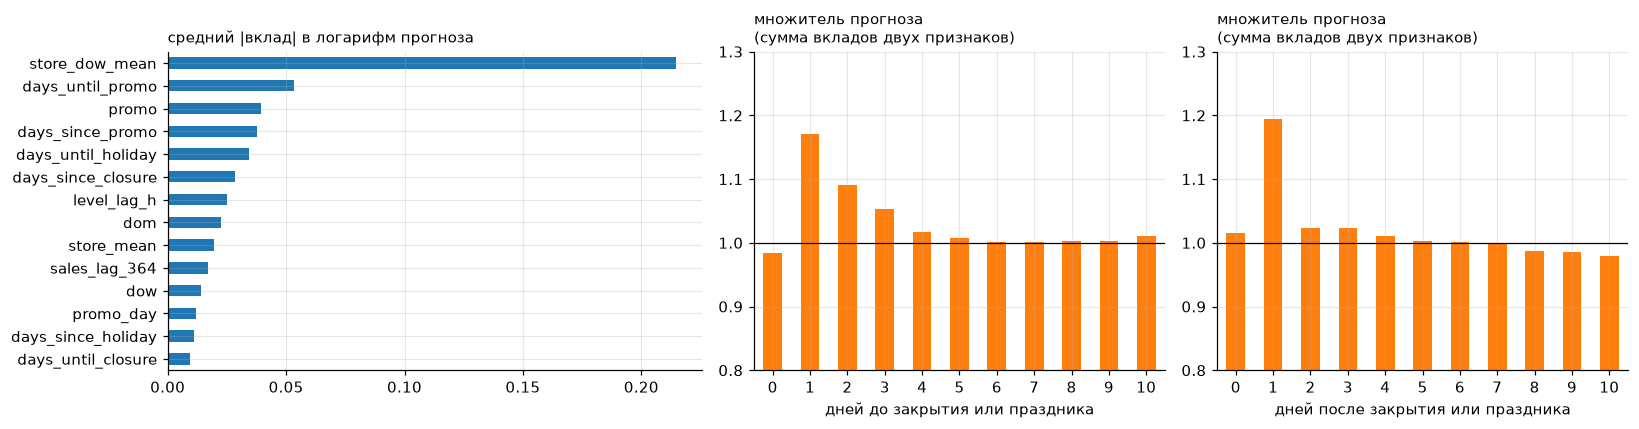

In [18]:
W = 1
f, cutoff, model = window_features[W], cutoffs[W], gbm_models[W]
mask = test_mask(cutoff)
X = f.loc[mask, BUSINESS]
contributions = model.predict(X, pred_contrib=True)
shap = pd.DataFrame(contributions[:, :-1], columns=BUSINESS, index=X.index)
open_days = stores.loc[mask, "open"].values == 1

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1.3, 1, 1]})
shap[open_days].abs().mean().sort_values().tail(14).plot.barh(ax=axes[0], color="C0")
axes[0].set_title("средний |вклад| в логарифм прогноза", loc="left", fontsize=10)
pairs = [
    ("days_until_closure", "days_until_holiday", "дней до закрытия или праздника"),
    ("days_since_closure", "days_since_holiday", "дней после закрытия или праздника"),
]
for ax, (closure, holiday, title) in zip(axes[1:], pairs):
    distance = X.loc[open_days, [closure, holiday]].min(axis=1)
    factor = np.exp(shap.loc[open_days, [closure, holiday]].sum(axis=1)).groupby(distance).mean()
    factor = factor[factor.index <= 10].set_axis(factor.index[factor.index <= 10].astype(int))
    factor.plot.bar(ax=ax, color="C1", rot=0)
    ax.axhline(1, color="k", lw=0.8)
    ax.set_ylim(0.8, max(1.3, factor.max() + 0.05))
    ax.set_title("множитель прогноза\n(сумма вкладов двух признаков)", loc="left", fontsize=10)
    ax.set_xlabel(title)
fig.tight_layout()

- Слева глобальная важность. Первое место у уровня магазина по дням недели: прогноз в основном это «обычные продажи этого магазина в этот день недели». Дальше промо и расстояния до него, праздники и закрытия, уровень последних недель.
- В центре и справа то, ради чего мы придумывали признаки. Накануне закрытия или праздника прогноз выше примерно на 17%, за два дня на 9%, в первый день после закрытия на 19%. Так модель выучила закупки перед праздником и после него.
- Обратите внимание на подписи: мы сложили вклады двух признаков, «дней до закрытия» и «дней до праздника». Они почти совпадают (магазины закрываются в праздники), и модель в разных деревьях берёт то один, то другой. SHAP делит эффект между ними, и по одному признаку эффект не виден вовсе. Общее правило: важность коррелирующих признаков смотрят по группе.

Теперь разложим прогноз одного магазина на группы признаков. Берём магазин, у которого вклад закрытий и праздников больше всего.

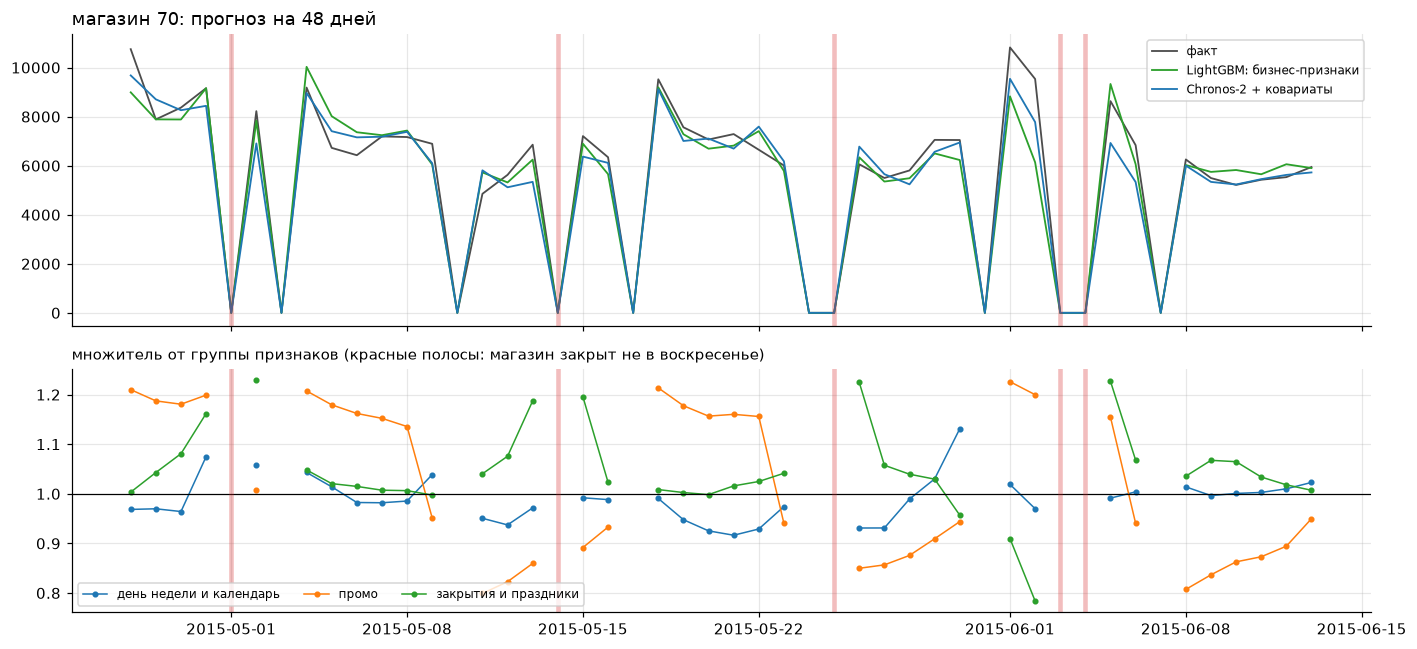

In [19]:
GROUP_OF = {
    "уровень магазина": [*STORE_LEVEL, "level_lag_h", "sales_lag_364"],
    "день недели и календарь": ["dow", "dom", "month", "woy", "doy"],
    "промо": ["promo", "promo_day", "days_until_promo", "days_since_promo"],
    "закрытия и праздники": [
        "state_holiday",
        "school_holiday",
        "days_until_closure",
        "days_since_closure",
        "days_until_holiday",
        "days_since_holiday",
    ],
    "Promo2, конкуренты, тип": [
        "promo2_active",
        "promo2_weeks",
        "competition_months",
        "competition_distance",
        "store_type",
        "assortment",
    ],
}
by_group = pd.DataFrame({g: shap[cols].sum(axis=1) for g, cols in GROUP_OF.items()})
test_rows = stores[mask]
store = by_group["закрытия и праздники"].abs().groupby(test_rows.store.values).sum().idxmax()
rows = (test_rows.store == store).values

fig, axes = plt.subplots(
    2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]}
)
day = test_rows.date[rows]
axes[0].plot(day, test_rows.sales[rows], color="0.3", lw=1.2, label="факт")
for name, color in [("LightGBM: бизнес-признаки", "C2"), ("Chronos-2 + ковариаты", "C0")]:
    axes[0].plot(day, window_preds[W][name][rows], color=color, lw=1.2, label=name)
axes[0].set_title(f"магазин {store}: прогноз на 48 дней", loc="left")
axes[0].legend(fontsize=8)
for g in ["день недели и календарь", "промо", "закрытия и праздники"]:
    factor = np.exp(by_group.loc[rows, g]).where(test_rows.open[rows] == 1)
    axes[1].plot(day, factor, marker="o", ms=3, lw=1, label=g)
axes[1].axhline(1, color="k", lw=0.8)
for closed_day in day[(test_rows.open[rows] == 0) & (day.dt.dayofweek != 6)]:
    for ax in axes:
        ax.axvline(closed_day, color="C3", alpha=0.3, lw=3)
axes[1].set_title(
    "множитель от группы признаков (красные полосы: магазин закрыт не в воскресенье)",
    loc="left",
    fontsize=10,
)
axes[1].legend(fontsize=8, ncol=3)
fig.tight_layout()

По нижнему графику прогноз можно объяснить словами: «в среду 13 мая прогноз выше обычного примерно на 20%, потому что в четверг праздник и магазин закрыт; в промонедели промо поднимает прогноз примерно на 15–20% относительно среднего, в недели без промо опускает». Такое объяснение можно проверить с бизнесом и поправить признак, если логика неверна.

**У Chronos-2 так просто не получится.** Встроенного разложения у него нет. Универсальные методы вроде KernelSHAP применимы к любой модели, но для рядов дороги: на каждый вклад нужны десятки прогонов и решение, чем заменить «выключенный» вход. Поэтому остаётся третий вопрос, «что если»: менять вход и смотреть, как меняется прогноз. Мы уже делали это на синтетике со скидкой. Сделаем то же с промо на Rossmann и для честности применим тот же приём к LightGBM. Два сценария для того же окна:
- **промо сдвигаем на неделю**: промонедели становятся обычными и наоборот. Такие расписания модели видели в истории много раз;
- **промо убираем совсем** на все 48 дней. Так в истории Rossmann не было никогда: промо идёт через неделю.

In [20]:
def scenario(promo_in_window):
    frame = stores.copy()
    frame.loc[mask, "promo"] = promo_in_window(frame)
    fx = add_store_level(make_features(frame), frame, cutoff)
    return (
        frame,
        predict_gbm(model, fx, frame, cutoff, BUSINESS),
        predict_chronos(frame, fx, cutoff, CHRONOS_COVARIATES),
    )


_, gbm_base, chronos_base = scenario(lambda frame: frame.loc[mask, "promo"])
shifted, gbm_shift, chronos_shift = scenario(
    lambda frame: frame.groupby("store").promo.shift(7)[mask].fillna(0)
)
_, gbm_none, chronos_none = scenario(lambda frame: 0.0)

was_promo = (stores.loc[mask, "promo"].values == 1) & open_days
now_promo = (shifted.loc[mask, "promo"].values == 1) & open_days
history = stores[(stores.date < cutoff) & (stores.open == 1) & (stores.date.dt.dayofweek < 5)]
empirical = history.groupby("promo").sales.mean()
print(
    f"в истории продажи в будни с промо выше, чем без него, на {empirical[1] / empirical[0] - 1:.0%}"
)
pd.DataFrame(
    {
        model_name: {
            "сдвиг: прирост в новые дни промо": np.mean(
                shift[now_promo & ~was_promo] / base[now_promo & ~was_promo]
            )
            - 1,
            "сдвиг: падение в бывшие дни промо": np.mean(
                shift[was_promo & ~now_promo] / base[was_promo & ~now_promo]
            )
            - 1,
            "промо убрали: прирост в дни промо": np.mean(base[was_promo] / none[was_promo]) - 1,
        }
        for model_name, base, shift, none in [
            ("LightGBM", gbm_base, gbm_shift, gbm_none),
            ("Chronos-2 + ковариаты", chronos_base, chronos_shift, chronos_none),
        ]
    }
).round(3)

в истории продажи в будни с промо выше, чем без него, на 39%


,LightGBM,Chronos-2 + ковариаты
сдвиг: прирост в новые дни промо,0.343,0.346
сдвиг: падение в бывшие дни промо,-0.273,-0.248
промо убрали: прирост в дни промо,0.165,0.399


Что видно:
- **простую частую ковариату Chronos-2 понимает хорошо**: при сдвиге промо прогноз сдвигается вслед за ним, и эффект промо примерно такой же, как в данных. В истории каждого магазина больше 60 промонедель, выучить эффект по контексту есть из чего. Слабость foundation-модели не в том, что она игнорирует ковариаты, а в редком, новом и сложном: глубокая скидка, которой не было (раздел 2), закрытия перед праздниками, признаки, смысл которых нужно знать заранее (раздел 3);
- при сдвиге LightGBM тоже ведёт себя разумно. А вот сценарий «промо нет совсем» для него **вне распределения обучения**: признак `days_since_promo` в обучении никогда не был больше 9, а здесь доходит до 30. Дерево отвечает тем, что выучило для ближайшей области, и оценка эффекта промо в этом сценарии отличается от оценки при сдвиге. Значения Шепли и «что если» для бустинга честны только там, где у модели были данные. Это та же проблема, что ступенька на кривой скидки в разделе 2.

## 6. Итоги

| вопрос | ответ |
|---|---|
| бустинг или foundation-модель | без бизнес-признаков бустинг проигрывает (fev-bench, LightGBM на ковариатах и уровне магазина); с бизнес-признаками выигрывает у Chronos-2 в режиме zero-shot; дообученный Chronos-2 его догоняет, а среднее двух моделей лучше обеих |
| как Chronos-2 использует ковариаты | выводит их эффект из контекста каждого ряда, по сути подбирает зависимость заново для каждого прогноза; без дообучения на ваших данных модель не учится |
| где ковариаты в foundation-модели работают | частые и простые: промо через неделю, флаг «магазин закрыт», праздники, которые были в истории |
| где не работают | значения, которых не было в истории ряда (новая глубина скидки); признаки, смысл которых нужно знать заранее (дни до закрытия); свойства ряда, которые не меняются во времени |
| почему бустинг выигрывает | одна модель на все ряды: эффект скидки или праздника выучен по тысячам случаев, а не по десятку в одном ряду |
| что даёт дообучение Chronos-2 | то, что у рядов общее в их собственной шкале: на Rossmann ошибка в обычные дни упала на 16%; у праздников только на 10%, там бустинг с явным признаком точнее в 1.6 раза |
| чего не даёт дообучение | абсолютного уровня ковариаты: каждая ковариата стандартизуется по своему контексту, модель видит только, насколько значение необычно для этого ряда |
| как объяснить прогноз бустинга | значения Шепли: `predict(X, pred_contrib=True)` в LightGBM, вклады складываются в прогноз |
| как объяснить прогноз foundation-модели | экспериментом «что если»: меняем ковариату и смотрим на прогноз. Универсальные методы вроде KernelSHAP тоже применимы, но дороги |
| где врут объяснения бустинга | вне распределения обучения: дерево не экстраполирует и не интерполирует гладко |

На практике эти подходы совмещают. Самый простой вариант, среднее прогнозов, на Rossmann уже дал 0.230, лучше каждой модели по отдельности. Сложнее и обычно сильнее: прогноз foundation-модели подают бустингу как ещё один признак (стекинг), или бустинг учат на остатках foundation-модели, чтобы он поправил то, что зависит от бизнес-признаков.